总行数: 235674
清洗后有效记录数: 234877
气温统计(℃):
count    234877.000000
mean         23.768974
std           5.824500
min           1.800000
25%          20.000000
50%          25.000000
75%          28.000000
max          38.000000
Name: Celsius, dtype: float64


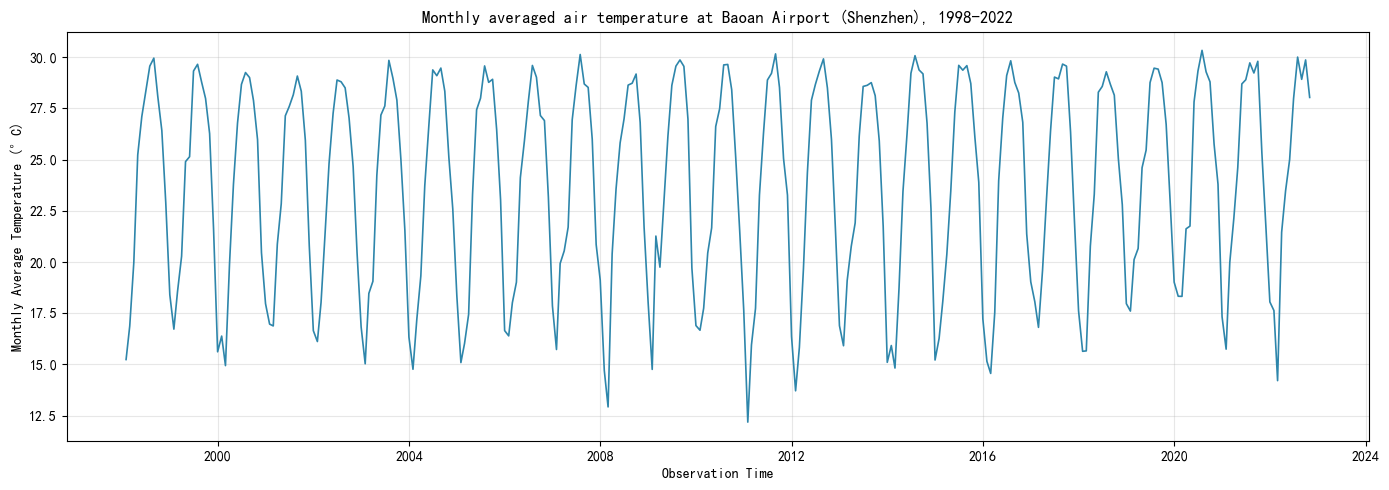

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# 1.读取数据
df = pd.read_csv("Baoan_Weather_1998_2022.csv", low_memory=False)
print("总行数:", len(df))

# 解析时间，设为索引
df["DATE"] = pd.to_datetime(df["DATE"])
df = df.set_index("DATE")

# 2.数据清洗
df_clean = df.copy()

# ① 提取逗号前的温度数值（TMP格式: "+0186,1"，逗号前为数值，逗号后为质控码）
df_clean["TMP_num"] = df_clean["TMP"].astype(str).str.split(",").str[0]
df_clean["TMP_num"] = pd.to_numeric(df_clean["TMP_num"], errors="coerce")

# ② 剔除缺失标记 9999（ISD规定9999代表观测缺失）和空值
df_clean = df_clean[df_clean["TMP_num"].notna() & (df_clean["TMP_num"] != 9999)]

# ③ 单位换算：TMP为十分之一摄氏度，除以10得摄氏度
df_clean["Celsius"] = df_clean["TMP_num"] / 10

# ④ 剔除超出深圳合理气温范围的异常值（0~40℃）
df_clean = df_clean[(df_clean["Celsius"] >= 0) & (df_clean["Celsius"] <= 40)]

print("清洗后有效记录数:", len(df_clean))
print("气温统计(℃):")
print(df_clean["Celsius"].describe())

# 3.按月重采样，计算月平均气温
monthly_temp = df_clean["Celsius"].resample("M").mean()

# 4.绘图：月平均气温时序图
plt.figure(figsize=(14, 5))
plt.plot(monthly_temp.index, monthly_temp.values, color="#2E86AB", linewidth=1.2)
plt.title("Monthly averaged air temperature at Baoan Airport (Shenzhen), 1998-2022")
plt.xlabel("Observation Time")
plt.ylabel("Monthly Average Temperature (°C)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

===== 3.1 Top 10 storms by WMO_WIND (SID + NAME) =====
                SID       NAME
3433  2015293N13266   PATRICIA
2082  1997253N12255      LINDA
2990  2009288N07267       RICK
1825  1994222N11267       JOHN
104   1959249N19181      PATSY
3453  2016041S14170    WINSTON
2451  2002295N11261      KENNA
656   1979275N06159        TIP
2065  1997212N11265  GUILLERMO
333   1973153N12266        AVA

===== 3.2 Top 20 storms wind speed =====
                SID       NAME  WMO_WIND
3433  2015293N13266   PATRICIA     185.0
2082  1997253N12255      LINDA     160.0
2990  2009288N07267       RICK     155.0
1825  1994222N11267       JOHN     150.0
104   1959249N19181      PATSY     150.0
3453  2016041S14170    WINSTON     150.0
2451  2002295N11261      KENNA     145.0
656   1979275N06159        TIP     140.0
2065  1997212N11265  GUILLERMO     140.0
333   1973153N12266        AVA     140.0
3029  2010169N13266      CELIA     140.0
3330  2014234N12261      MARIE     140.0
2441  2002242N14257     HERNA

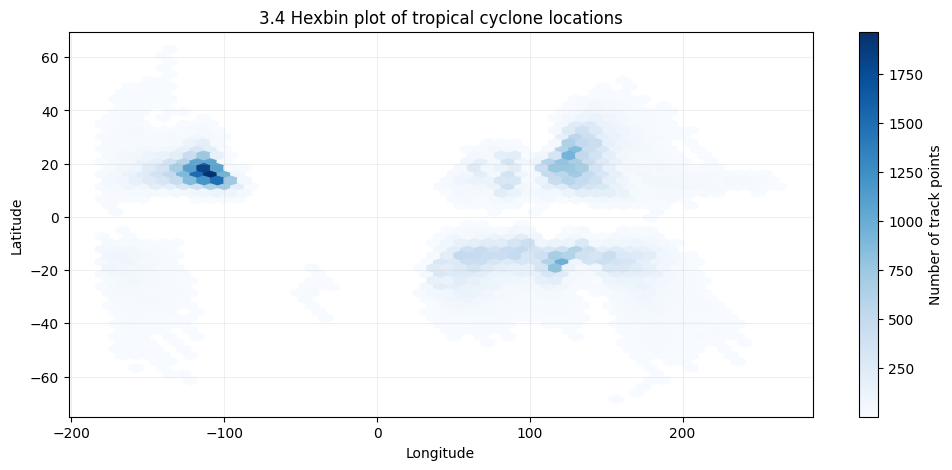


===== 3.5 Typhoon Mangkhut (2018) =====
                  SID      NAME            ISO_TIME     LAT      LON  WMO_WIND
683026  2018250N12170  MANGKHUT 2018-09-07 12:00:00  12.820  165.367      35.0
683028  2018250N12170  MANGKHUT 2018-09-07 18:00:00  13.075  163.800      35.0
683030  2018250N12170  MANGKHUT 2018-09-08 00:00:00  13.600  162.350      40.0
683032  2018250N12170  MANGKHUT 2018-09-08 06:00:00  14.300  160.825      40.0
683034  2018250N12170  MANGKHUT 2018-09-08 12:00:00  14.575  159.125      45.0
683036  2018250N12170  MANGKHUT 2018-09-08 18:00:00  14.750  157.125      50.0
683038  2018250N12170  MANGKHUT 2018-09-09 00:00:00  14.925  155.050      65.0
683040  2018250N12170  MANGKHUT 2018-09-09 06:00:00  15.300  153.025      65.0
683042  2018250N12170  MANGKHUT 2018-09-09 12:00:00  15.150  151.225      70.0
683044  2018250N12170  MANGKHUT 2018-09-09 18:00:00  14.650  149.125      80.0
683046  2018250N12170  MANGKHUT 2018-09-10 00:00:00  14.525  147.450      80.0
683048  201

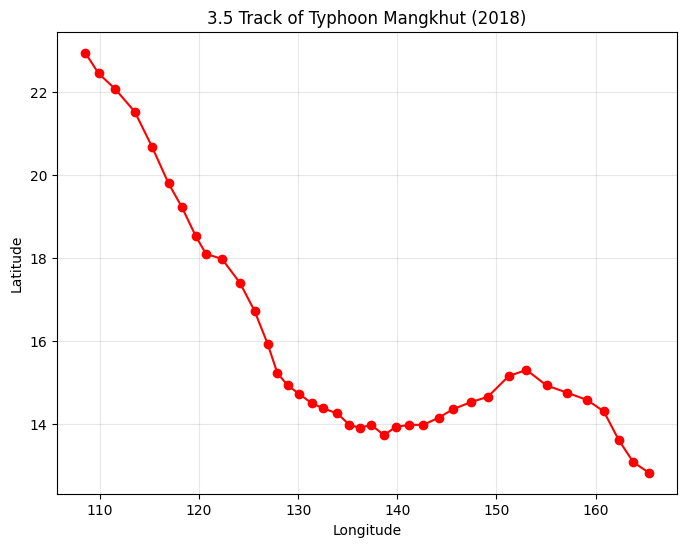


===== 3.6 Subset (>=1970, WP+EP) total points: 52023 =====


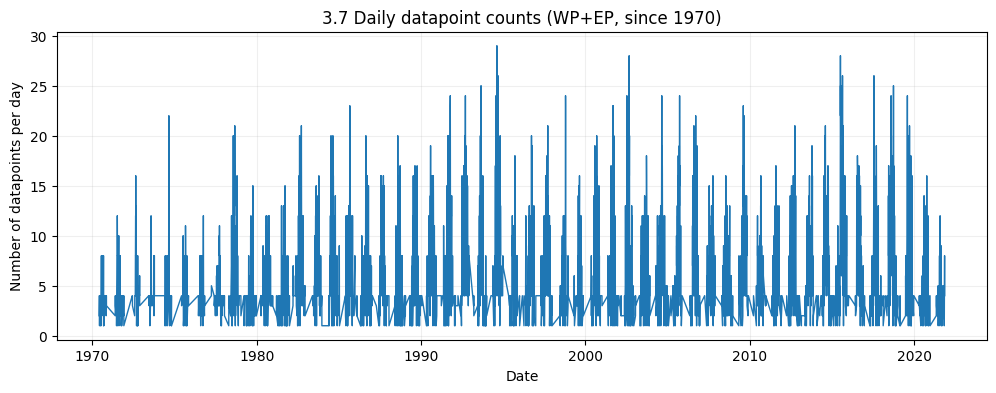

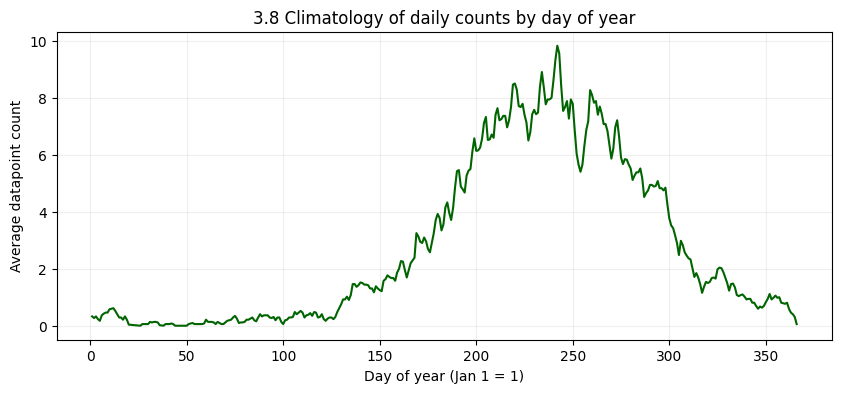

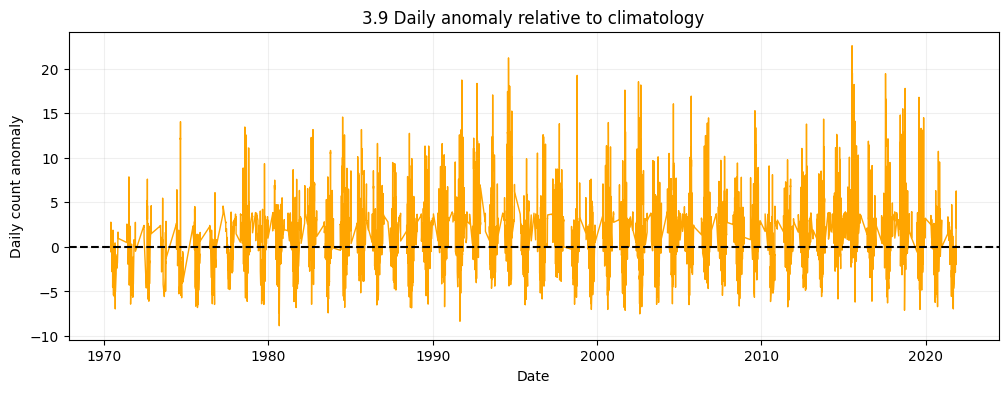

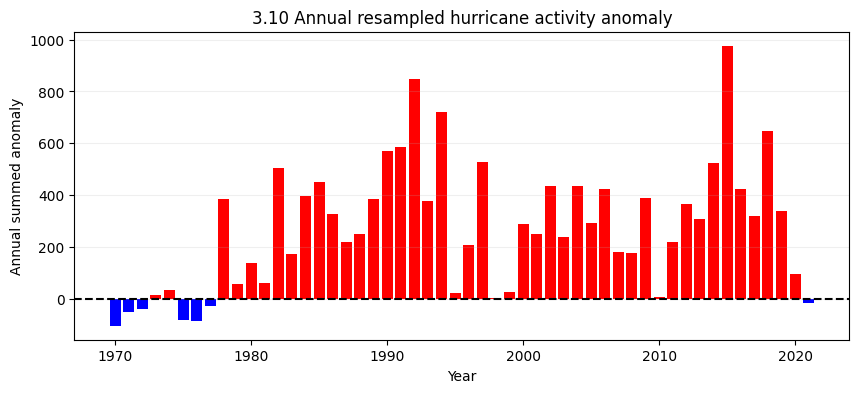

In [2]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv(
    'ibtracs.ALL.list.v04r00.csv',
    usecols=range(17),
    skiprows=[1, 2],
    parse_dates=['ISO_TIME'],
    na_values=['NOT_NAMED', 'NAME'],
    engine="python"
)

# 基础清洗
df["WMO_WIND"] = pd.to_numeric(df["WMO_WIND"], errors="coerce")
df = df.dropna(subset=["WMO_WIND", "LAT", "LON", "ISO_TIME", "BASIN"])
df = df[df["WMO_WIND"] > 0]

# ---------------- 3.1 Group by SID，10个风速最大风暴，输出SID+NAME ----------------
print("===== 3.1 Top 10 storms by WMO_WIND (SID + NAME) =====")
storm_maxwind = df.groupby("SID")["WMO_WIND"].max().reset_index()
storm_info = df[["SID", "NAME"]].drop_duplicates("SID")
storm_merge = pd.merge(storm_maxwind, storm_info, on="SID", how="left")
top10_storm = storm_merge.sort_values("WMO_WIND", ascending=False).head(10)
print(top10_storm[["SID", "NAME"]])

# ---------------- 3.2 20个风速最强风暴，列出风速 ----------------
print("\n===== 3.2 Top 20 storms wind speed =====")
top20_storm = storm_merge.sort_values("WMO_WIND", ascending=False).head(20)
print(top20_storm[["SID", "NAME", "WMO_WIND"]])

# ---------------- 3.3 Count datapoints by Basin（全部盆地，不能提前筛WP！） ----------------
print("\n===== 3.3 Count datapoints by Basin =====")
basin_count = df["BASIN"].value_counts()
print(basin_count)

# ---------------- 3.4 hexbin plot of lat/lon 全球hexbin图 ----------------
plt.figure(figsize=(12, 5))
hb = plt.hexbin(df["LON"], df["LAT"], gridsize=50, cmap="Blues", mincnt=1)
plt.colorbar(hb, label="Number of track points")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("3.4 Hexbin plot of tropical cyclone locations")
plt.grid(alpha=0.2)
plt.show()

# ---------------- 3.5 2018 Mangkhut 山竹路径 ----------------
print("\n===== 3.5 Typhoon Mangkhut (2018) =====")
mangkhut = df[(df["NAME"] == "MANGKHUT") & (df["ISO_TIME"].dt.year == 2018)].copy()
print(mangkhut[["SID","NAME","ISO_TIME","LAT","LON","WMO_WIND"]])

plt.figure(figsize=(8,6))
plt.plot(mangkhut["LON"], mangkhut["LAT"], marker="o", c="red", linewidth=1.5)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("3.5 Track of Typhoon Mangkhut (2018)")
plt.grid(alpha=0.3)
plt.show()

# ---------------- 3.6 筛选：1970之后，WP 和 EP 盆地，后面全部任务用这个子集！ ----------------
df_sub = df[(df["ISO_TIME"].dt.year >= 1970) & (df["BASIN"].isin(["WP", "EP"]))].copy()
print(f"\n===== 3.6 Subset (>=1970, WP+EP) total points: {len(df_sub)} =====")

# ---------------- 3.7 每日数据点数量绘图 ----------------
df_sub["date"] = df_sub["ISO_TIME"].dt.date
daily_cnt = df_sub.groupby("date").size().reset_index(name="count")

plt.figure(figsize=(12,4))
plt.plot(daily_cnt["date"], daily_cnt["count"], lw=1)
plt.xlabel("Date")
plt.ylabel("Number of datapoints per day")
plt.title("3.7 Daily datapoint counts (WP+EP, since 1970)")
plt.grid(alpha=0.2)
plt.show()

# ---------------- 3.8 day-of-year气候态（一年第几天，1月1日=1） ----------------
df_sub["dayofyear"] = df_sub["ISO_TIME"].dt.dayofyear
climatology = (df_sub.groupby("dayofyear").size() / df_sub["ISO_TIME"].dt.year.nunique()).rename("clim_mean")

plt.figure(figsize=(10,4))
plt.plot(climatology.index, climatology.values, c="darkgreen")
plt.xlabel("Day of year (Jan 1 = 1)")
plt.ylabel("Average datapoint count")
plt.title("3.8 Climatology of daily counts by day of year")
plt.grid(alpha=0.2)
plt.show()

# ---------------- 3.9 逐日距平：当日数量 - 该日气候态均值 ----------------
df_sub["date"] = df_sub["ISO_TIME"].dt.date
daily_cnt = df_sub.groupby("date").size().reset_index(name="count")
daily_cnt["dayofyear"] = pd.to_datetime(daily_cnt["date"]).dt.dayofyear

# merge 气候态
daily_cnt = daily_cnt.merge(climatology.reset_index(), on="dayofyear", how="left")
daily_cnt["anomaly"] = daily_cnt["count"] - daily_cnt["clim_mean"]

plt.figure(figsize=(12,4))
plt.plot(daily_cnt["date"], daily_cnt["anomaly"], c="orange", lw=1)
plt.axhline(y=0, c="k", ls="--")
plt.xlabel("Date")
plt.ylabel("Daily count anomaly")
plt.title("3.9 Daily anomaly relative to climatology")
plt.grid(alpha=0.2)
plt.show()

# ---------------- 3.10 重采样到年尺度，画距平，识别异常年份 ----------------
daily_cnt["datetime"] = pd.to_datetime(daily_cnt["date"])
daily_cnt = daily_cnt.set_index("datetime")
annual_anom = daily_cnt["anomaly"].resample("Y").sum()

plt.figure(figsize=(10,4))
colors = ["r" if v>0 else "b" for v in annual_anom.values]
plt.bar(annual_anom.index.year, annual_anom.values, color=colors)
plt.axhline(0, c="k", ls="--")
plt.xlabel("Year")
plt.ylabel("Annual summed anomaly")
plt.title("3.10 Annual resampled hurricane activity anomaly")
plt.grid(axis="y", alpha=0.2)
plt.show()

原始数据行数： 9350
清洗后数据行数： 9350

清洗后数据预览：
                 time         mf
0 1978-07-01 00:04:00  159.12134
1 1978-07-01 04:07:00  157.21630
2 1978-07-01 05:08:00  158.11868
3 1978-07-01 06:09:00  157.21630
4 1978-07-03 01:01:00  156.31389


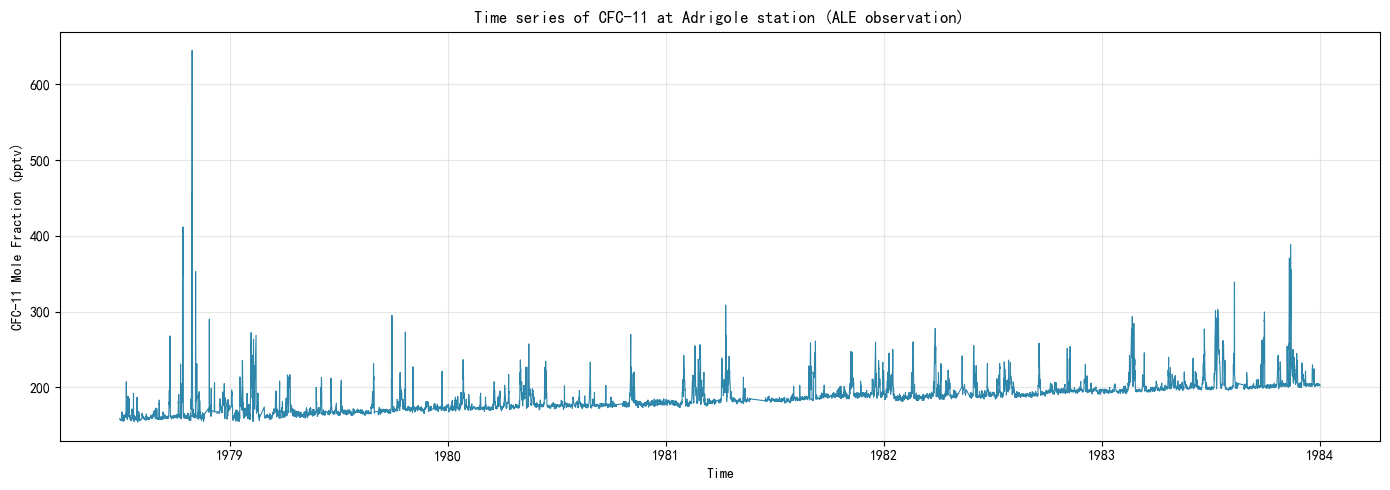

===== 【统计检查1：基础描述统计】 =====
均值 = 185.821 pptv
标准差 = 21.903 pptv
中位数 = 183.887 pptv

===== 【统计检查2：长期线性趋势显著性检验】 =====
斜率(每天变化量) = 0.0222 pptv/day
R² = 0.3795
P值 = 0.00e+00
结论：长期趋势统计显著（p<0.05）

===== 【统计检查3：季节变化分析（按月分组平均）】 =====
各月平均CFC-11浓度：
month
1     184.041622
2     191.247069
3     183.943146
4     188.856176
5     187.598658
6     187.467797
7     181.628000
8     180.543537
9     182.056514
10    186.972403
11    189.149078
12    190.233820
Name: mf, dtype: float64


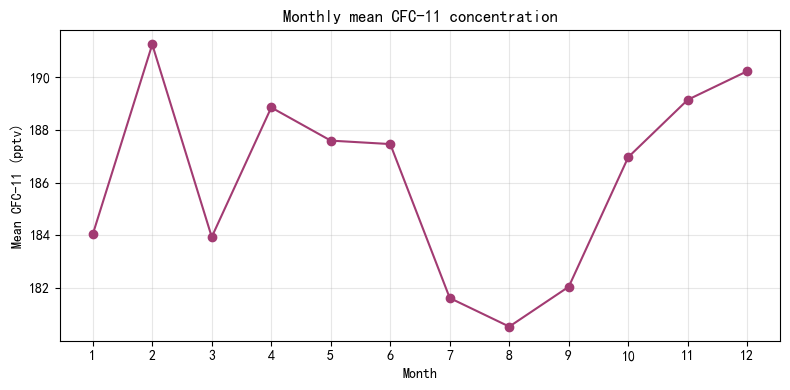


===== 【统计检查4：3σ异常值检测】 =====
阈值下限 120.110, 阈值上限 251.531
识别异常样本数量：117
异常样本前5条：
                   time         mf
740 1978-09-22 23:06:00  268.00964
741 1978-09-23 00:07:00  266.70620
939 1978-10-14 04:10:00  351.63110
940 1978-10-14 05:11:00  347.41992
941 1978-10-14 06:12:00  351.33026

===== 【统计检查5：自相关检验（时序持续性）】 =====


<Figure size 800x400 with 0 Axes>

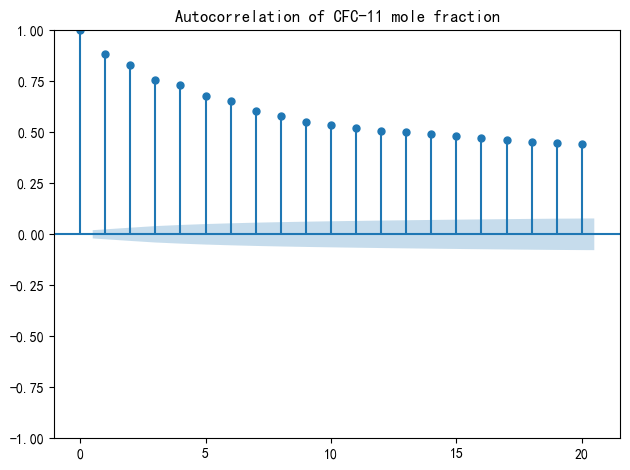

自相关图解读：若前几阶落在置信区间外，说明观测存在时间相关性


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf

# ===================== 4.1 加载csv，清洗缺失值、坏质量数据 =====================
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 读取csv，自动解析时间列
df = pd.read_csv("cfc11_adrigole.csv", parse_dates=["time"])
print("原始数据行数：", len(df))

# 清洗步骤
# 1. 删除mf为空的缺失记录
df_clean = df.dropna(subset=["mf"]).copy()
# 2. 剔除明显不合理负值
df_clean = df_clean[df_clean["mf"] > 0]
# 3. 按时间排序
df_clean = df_clean.sort_values("time").reset_index(drop=True)

print("清洗后数据行数：", len(df_clean))
print("\n清洗后数据预览：")
print(df_clean[["time", "mf"]].head())

# ===================== 4.2 绘制CFC-11摩尔分数时间序列图 =====================
plt.figure(figsize=(14,5))
plt.plot(df_clean["time"], df_clean["mf"], color="#2E86AB", linewidth=0.8)
plt.xlabel("Time")
plt.ylabel("CFC-11 Mole Fraction (pptv)")
plt.title("Time series of CFC-11 at Adrigole station (ALE observation)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ===================== 4.3 至少5项统计检验与结果输出 =====================
mf_data = df_clean["mf"].values
time_dt = df_clean["time"]

print("===== 【统计检查1：基础描述统计】 =====")
mean_mf = np.mean(mf_data)
std_mf = np.std(mf_data, ddof=1)
median_mf = np.median(mf_data)
print(f"均值 = {mean_mf:.3f} pptv")
print(f"标准差 = {std_mf:.3f} pptv")
print(f"中位数 = {median_mf:.3f} pptv")

print("\n===== 【统计检查2：长期线性趋势显著性检验】 =====")
# 把时间转为浮点（从起始天数）
t_days = (time_dt - time_dt.iloc[0]).dt.total_seconds() / (3600*24)
slope, intercept, r_value, p_value, std_err = stats.linregress(t_days, mf_data)
print(f"斜率(每天变化量) = {slope:.4f} pptv/day")
print(f"R² = {r_value**2:.4f}")
print(f"P值 = {p_value:.2e}")
if p_value < 0.05:
    print("结论：长期趋势统计显著（p<0.05）")
else:
    print("结论：长期趋势不显著")

print("\n===== 【统计检查3：季节变化分析（按月分组平均）】 =====")
df_clean["month"] = df_clean["time"].dt.month
monthly_mean = df_clean.groupby("month")["mf"].mean()
print("各月平均CFC-11浓度：")
print(monthly_mean)
# 画季节图
plt.figure(figsize=(8,4))
plt.plot(monthly_mean.index, monthly_mean.values, marker='o', c="#A23B72")
plt.xlabel("Month")
plt.ylabel("Mean CFC-11 (pptv)")
plt.title("Monthly mean CFC-11 concentration")
plt.xticks(range(1,13))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\n===== 【统计检查4：3σ异常值检测】 =====")
upper = mean_mf + 3 * std_mf
lower = mean_mf - 3 * std_mf
outliers = df_clean[(df_clean["mf"] > upper) | (df_clean["mf"] < lower)]
print(f"阈值下限 {lower:.3f}, 阈值上限 {upper:.3f}")
print(f"识别异常样本数量：{len(outliers)}")
if len(outliers) > 0:
    print("异常样本前5条：")
    print(outliers[["time","mf"]].head())

print("\n===== 【统计检查5：自相关检验（时序持续性）】 =====")
plt.figure(figsize=(8,4))
plot_acf(mf_data, lags=20, alpha=0.05)
plt.title("Autocorrelation of CFC-11 mole fraction")
plt.tight_layout()
plt.show()
print("自相关图解读：若前几阶落在置信区间外，说明观测存在时间相关性")

列名：
['Search Parameters', 'Year', 'Mo', 'Dy', 'Hr', 'Mn', 'Sec', 'Tsu', 'Vol', 'Location Name', 'Latitude', 'Longitude', 'Focal Depth (km)', 'Mag', 'MMI Int', 'Deaths', 'Death Description', 'Missing', 'Missing Description', 'Injuries', 'Injuries Description', 'Damage ($Mil)', 'Damage Description', 'Houses Destroyed', 'Houses Destroyed Description', 'Houses Damaged', 'Houses Damaged Description', 'Total Deaths', 'Total Death Description', 'Total Missing', 'Total Missing Description', 'Total Injuries', 'Total Injuries Description', 'Total Damage ($Mil)', 'Total Damage Description', 'Total Houses Destroyed', 'Total Houses Destroyed Description', 'Total Houses Damaged', 'Total Houses Damaged Description']

===== 1.1 死亡人数前20地区 =====
Location Name
CHINA:  SHAANXI PROVINCE                     830313.0
TURKEY:  ANTAKYA (ANTIOCH)                   434870.0
HAITI:  PORT-AU-PRINCE                       316000.0
IRAN:  TABRIZ                                268750.0
TURKEY:  ANTAKYA (ANTIOCH), SAMA

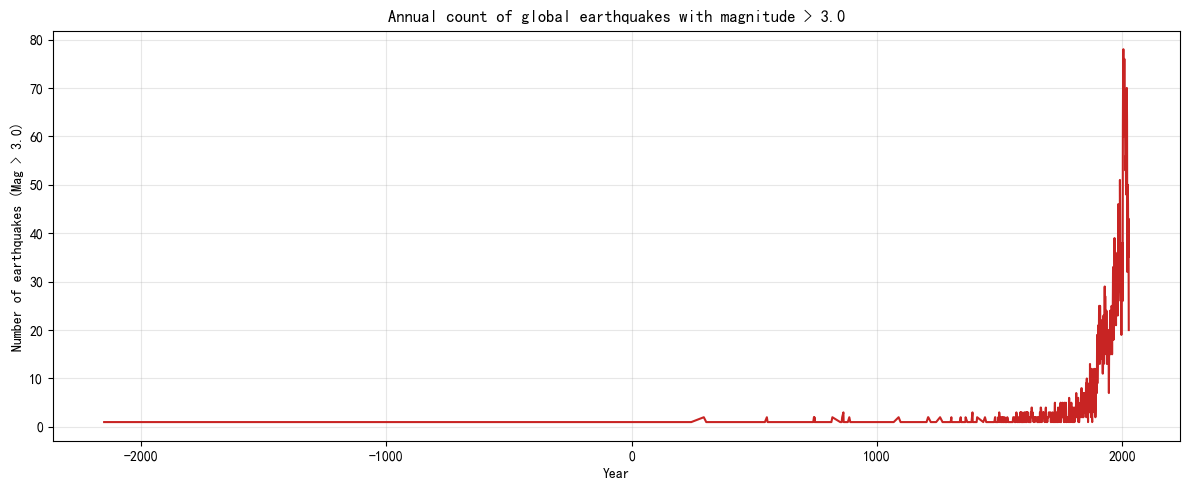


===== 1.2 每年Mag>3.0地震数量（前10） =====
Year
-2150.0    1
-2000.0    1
-1250.0    1
-1050.0    1
-479.0     1
-426.0     1
-400.0     1
-373.0     1
-330.0     1
-250.0     1
dtype: int64

===== 1.3 各地地震总数 + 该地最大地震信息（降序） =====
                              Location Name  Total_EQ_count   Largest_EQ_date  \
0                   CHINA:  YUNNAN PROVINCE              68    1833.0-9.0-6.0   
1                    RUSSIA:  KURIL ISLANDS              53  1963.0-10.0-13.0   
2                  CHINA:  SICHUAN PROVINCE              46   2008.0-5.0-12.0   
3                                    TURKEY              45    1944.0-2.0-1.0   
4                           VANUATU ISLANDS              40  1913.0-10.0-14.0   
...                                     ...             ...               ...   
4117        TRINIDAD; GRENADA:  ST GEORGE'S               1   1888.0-1.0-10.0   
4118   INDONESIA:  SUMATERA:  BREUEH ISLAND               1   1888.0-3.0-21.0   
4119                      URUGUAY:  COLOGNE     

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

Sig_Eqs = pd.read_csv("earthquakes-2026-10-28_15-57-39_+0800.tsv", sep="\t")
Sig_Eqs.columns = Sig_Eqs.columns.str.strip()
print("列名：")
print(Sig_Eqs.columns.tolist())

# ========= 1.1 每个地点死亡总人数，输出前20 =========
death_by_country = Sig_Eqs.groupby("Location Name")["Deaths"].sum().fillna(0)
death_top20 = death_by_country.sort_values(ascending=False).head(20)

print("\n===== 1.1 死亡人数前20地区 =====")
print(death_top20)

# ========= 1.2 每年全球 Mag >3.0 的地震数量，画时序图 =========
eq_mag3 = Sig_Eqs[Sig_Eqs["Mag"] > 3.0].copy()
count_yearly = eq_mag3.groupby("Year").size()

plt.figure(figsize=(12, 5))
count_yearly.plot(color="#c82423")
plt.xlabel("Year")
plt.ylabel("Number of earthquakes (Mag > 3.0)")
plt.title("Annual count of global earthquakes with magnitude > 3.0")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\n===== 1.2 每年Mag>3.0地震数量（前10） =====")
print(count_yearly.head(10))

# ========= 1.3 函数 CountEq_LargestEq =========
def CountEq_LargestEq(country_name):
    sub = Sig_Eqs[Sig_Eqs["Location Name"] == country_name].copy()
    total_count = len(sub)
    if total_count == 0:
        return (0, None, None)
    # 防止Mag全为空报错，加一层判断
    if sub["Mag"].isna().all():
        max_eq = sub.iloc[0]
    else:
        max_eq = sub.loc[sub["Mag"].idxmax()]
    y = max_eq["Year"]
    mo = max_eq["Mo"]
    dy = max_eq["Dy"]
    date_str = f"{y}-{mo}-{dy}"
    loc = max_eq["Location Name"]
    return (total_count, date_str, loc)

all_countries = Sig_Eqs["Location Name"].dropna().unique()
result_list = []
for ctry in all_countries:
    if pd.isna(ctry):
        continue
    cnt, eq_date, eq_loc = CountEq_LargestEq(ctry)
    result_list.append({
        "Location Name": ctry,
        "Total_EQ_count": cnt,
        "Largest_EQ_date": eq_date,
        "Largest_EQ_location": eq_loc
    })

result_df = pd.DataFrame(result_list)
result_df_sorted = result_df.sort_values("Total_EQ_count", ascending=False).reset_index(drop=True)

print("\n===== 1.3 各地地震总数 + 该地最大地震信息（降序） =====")
print(result_df_sorted)